# Proyecto 12 – Datos
**Sistema de detección de transacciones financieras sospechosas**

Este notebook se encarga de adquirir los datos con procedencia documentada, realizar el EDA, la limpieza y las particiones train/valid/test evitando fuga de información, como lo pide el proyecto.

Al final deja listos:
- `datos_procesados/train.parquet`, `valid.parquet`, `test.parquet` para entrenar el modelo.
- `datos_procesados/clientes.csv`, `comercios.csv`, `transacciones.csv` como ejemplo de estructura para la base de datos (opcionales).
- `datos_procesados/metadata_datos.json` y `diccionario_datos.csv` como evidencia de procedencia.

## 1. Procedencia de los datos

| Campo | Valor |
|---|---|
| Nombre | Credit Card Transactions Fraud Detection Dataset |
| Fuente | Kaggle – kartik2112/fraud-detection |
| URL | https://www.kaggle.com/datasets/kartik2112/fraud-detection |
| Cómo se generó | Simulado con *Sparkov Data Generation* (Brandon Harris), entre el 1-ene-2019 y el 31-dic-2020 |
| Contenido real de los archivos | 1.852.394 transacciones, 999 clientes (tarjetas distintas) y 693 comercios distintos |
| Archivos | `fraudTrain.csv` (1.296.675 filas) y `fraudTest.csv` (555.719 filas) |
| Fecha de descarga | 21 de noviembre de 2026 |
| Datos personales | Ficticios (generados con la librería *faker*); no corresponden a personas reales |

> La descripción de Kaggle habla de "1.000 clientes y 800 comercios" como parámetros de la simulación. Al contar los valores distintos en los archivos descargados salen 999 clientes y 693 comercios: no falta información, simplemente esos son los que quedaron en los datos generados.

Los archivos originales se guardan **sin modificar** en `dataset/`. Toda limpieza se hace en este notebook, para que el proceso sea reproducible.

In [1]:
import json
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import variables as V  # definiciones compartidas con el modelo y la API (debe estar en la misma carpeta)

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (9, 4)

# ---------------- Configuración ----------------
BASE = Path("C:/Users/isalo/Desktop/universidad/9.Semestre_9/Big data/Proyecto Final")

RUTA_CRUDOS = BASE / "dataset"               # aquí van fraudTrain.csv y fraudTest.csv
RUTA_PROCESADOS = BASE / "datos_procesados"  # aquí se guardan los resultados
RUTA_PROCESADOS.mkdir(exist_ok=True)

TASA_COP_POR_USD = 3500   # tasa fija documentada: 1 USD = 3.500 COP (la misma debe usar el backend)
SEMILLA = 42
PROPORCION_VALID = 0.20   # último 20 % (por fecha) de fraudTrain se usa como validación

## 2. Carga
Se cargan los dos archivos y se marca de cuál viene cada fila. `fraudTest.csv` contiene transacciones **posteriores** a las de `fraudTrain.csv`, así que se usará como conjunto de prueba.

In [2]:
train_crudo = pd.read_csv(RUTA_CRUDOS / "fraudTrain.csv")
test_crudo = pd.read_csv(RUTA_CRUDOS / "fraudTest.csv")
train_crudo["archivo_origen"] = "fraudTrain"
test_crudo["archivo_origen"] = "fraudTest"

df = pd.concat([train_crudo, test_crudo], ignore_index=True)
print("fraudTrain:", train_crudo.shape, "| fraudTest:", test_crudo.shape, "| total:", df.shape)
df.head()

fraudTrain: (1296675, 24) | fraudTest: (555719, 24) | total: (1852394, 24)


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,archivo_origen
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,fraudTrain
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,fraudTrain
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,fraudTrain
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,fraudTrain
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,fraudTrain


## 3. Inspección inicial
Tipos de dato, valores nulos, duplicados y rango de fechas.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1852394 entries, 0 to 1852393
Data columns (total 24 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Unnamed: 0             int64  
 1   trans_date_trans_time  str    
 2   cc_num                 int64  
 3   merchant               str    
 4   category               str    
 5   amt                    float64
 6   first                  str    
 7   last                   str    
 8   gender                 str    
 9   street                 str    
 10  city                   str    
 11  state                  str    
 12  zip                    int64  
 13  lat                    float64
 14  long                   float64
 15  city_pop               int64  
 16  job                    str    
 17  dob                    str    
 18  trans_num              str    
 19  unix_time              int64  
 20  merch_lat              float64
 21  merch_long             float64
 22  is_fraud               int64 

In [4]:
print("Nulos por columna:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().any() else "  ninguno")
print("\nFilas duplicadas:", df.duplicated().sum())
print("trans_num repetidos:", df["trans_num"].duplicated().sum())
print("Rango de fechas:", df["trans_date_trans_time"].min(), "->", df["trans_date_trans_time"].max())

Nulos por columna:
  ninguno

Filas duplicadas: 0
trans_num repetidos: 0
Rango de fechas: 2019-01-01 00:00:18 -> 2020-12-31 23:59:34


## 4. Renombrar columnas a español
Se renombran para que coincidan con los nombres de la base de datos y del contrato de la API.

In [5]:
NOMBRES = {
    "Unnamed: 0": "indice_original",
    "trans_date_trans_time": "fecha_hora",
    "cc_num": "tarjeta",
    "merchant": "comercio",
    "category": "categoria",
    "amt": "monto",
    "first": "nombre",
    "last": "apellido",
    "gender": "genero",
    "street": "direccion",
    "city": "ciudad",
    "state": "estado",
    "zip": "codigo_postal",
    "lat": "cliente_lat",
    "long": "cliente_long",
    "city_pop": "poblacion_ciudad",
    "job": "ocupacion",
    "dob": "fecha_nacimiento",
    "trans_num": "id_origen",
    "unix_time": "tiempo_unix",
    "merch_lat": "comercio_lat",
    "merch_long": "comercio_long",
    "is_fraud": "es_fraude",
}
df = df.rename(columns=NOMBRES)


In [6]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1852394 entries, 0 to 1852393
Data columns (total 24 columns):
 #   Column            Dtype  
---  ------            -----  
 0   indice_original   int64  
 1   fecha_hora        str    
 2   tarjeta           int64  
 3   comercio          str    
 4   categoria         str    
 5   monto             float64
 6   nombre            str    
 7   apellido          str    
 8   genero            str    
 9   direccion         str    
 10  ciudad            str    
 11  estado            str    
 12  codigo_postal     int64  
 13  cliente_lat       float64
 14  cliente_long      float64
 15  poblacion_ciudad  int64  
 16  ocupacion         str    
 17  fecha_nacimiento  str    
 18  id_origen         str    
 19  tiempo_unix       int64  
 20  comercio_lat      float64
 21  comercio_long     float64
 22  es_fraude         int64  
 23  archivo_origen    str    
dtypes: float64(5), int64(6), str(13)
memory usage: 640.9 MB


## 5. Limpieza y transformación
En esta sección se ajusta el dataset al proyecto: se eliminan columnas que no aportan o son redundantes, se convierten los montos a pesos y se traducen las categorías al español, para que coincidan con los comercios de la aplicación.

| Paso | Por qué |
|---|---|
| Eliminar `indice_original`, `direccion`, `codigo_postal`, `tiempo_unix`, `poblacion_ciudad` | No se usan ni en el modelo ni en la app (el índice y `tiempo_unix` son redundantes) |
| Convertir fechas a `datetime` | Para calcular hora, día e historial |
| `monto` en COP (`amt × 3.500`) | Todo el sistema trabaja en pesos |
| Quitar el prefijo `fraud_` del nombre del comercio | En Sparkov todos los comercios empiezan así; no indica fraude y confunde en la app |
| Crear `cliente_id` (C-0001…) y `comercio_id` (M-0001…) | La app no guarda el número de tarjeta completo |
| Validar montos, coordenadas y categorías | Detectar datos inválidos antes de entrenar |
| Traducir las 14 categorías al español | Los comercios de la app estarán en español; el canal se obtiene de la tabla `V.CANAL_POR_CATEGORIA` |

In [7]:
df = df.drop(columns=["indice_original", "direccion", "codigo_postal", "tiempo_unix", "poblacion_ciudad"])

df["fecha_hora"] = pd.to_datetime(df["fecha_hora"])
df["fecha_nacimiento"] = pd.to_datetime(df["fecha_nacimiento"])
df["monto"] = (df["monto"] * TASA_COP_POR_USD).round(0)
df["comercio"] = df["comercio"].str.removeprefix("fraud_")

# IDs de cliente y comercio (ordenados para que sean reproducibles)
tarjetas = np.sort(df["tarjeta"].unique())
mapa_cliente = {t: f"C-{i+1:04d}" for i, t in enumerate(tarjetas)}
df["cliente_id"] = df["tarjeta"].map(mapa_cliente)
df["tarjeta_ultimos4"] = df["tarjeta"].astype(str).str[-4:]

comercios_unicos = np.sort(df["comercio"].unique())
mapa_comercio = {c: f"M-{i+1:04d}" for i, c in enumerate(comercios_unicos)}
df["comercio_id"] = df["comercio"].map(mapa_comercio)

print("Clientes:", df["cliente_id"].nunique(), "| Comercios:", df["comercio_id"].nunique())

Clientes: 999 | Comercios: 693


In [8]:
# Validaciones
CATEGORIAS = sorted(df["categoria"].unique())
print("Categorías (", len(CATEGORIAS), "):", CATEGORIAS)
print("Montos <= 0:", (df["monto"] <= 0).sum())
print("Latitudes fuera de rango:", (~df["cliente_lat"].between(-90, 90) | ~df["comercio_lat"].between(-90, 90)).sum())
print("Longitudes fuera de rango:", (~df["cliente_long"].between(-180, 180) | ~df["comercio_long"].between(-180, 180)).sum())

# ¿Cada comercio tiene una sola categoría? (la app copia la categoría desde el comercio)
cats_por_comercio = df.groupby("comercio_id")["categoria"].nunique()
print("Comercios con más de una categoría:", (cats_por_comercio > 1).sum())

Categorías ( 14 ): ['entertainment', 'food_dining', 'gas_transport', 'grocery_net', 'grocery_pos', 'health_fitness', 'home', 'kids_pets', 'misc_net', 'misc_pos', 'personal_care', 'shopping_net', 'shopping_pos', 'travel']
Montos <= 0: 0
Latitudes fuera de rango: 0
Longitudes fuera de rango: 0
Comercios con más de una categoría: 7


In [9]:
# Traducción de las 14 categorías al español.
# La tabla está en variables.py (V.TRADUCCION_CATEGORIAS) para que el notebook, el modelo y la API usen
# exactamente los mismos nombres. El backend debe enviar la categoría con uno de estos nombres.
pd.DataFrame({"codigo_dataset": list(V.TRADUCCION_CATEGORIAS.keys()),
              "categoria_espanol": list(V.TRADUCCION_CATEGORIAS.values())})

,codigo_dataset,categoria_espanol
0,entertainment,entretenimiento
1,food_dining,alimentación y restaurantes
2,gas_transport,gasolina y transporte
3,grocery_net,compras de supermercado en línea
4,grocery_pos,compras en supermercado
5,health_fitness,salud y bienestar
6,home,hogar
7,kids_pets,niños y mascotas
8,misc_net,compras diversas en línea
9,misc_pos,compras diversas en establecimientos


In [10]:
df["categoria"] = df["categoria"].map(V.TRADUCCION_CATEGORIAS)
assert df["categoria"].notna().all(), "Hay categorías sin traducción"


In [11]:
# Verificación: cada categoría en español con su canal.
# Antes el canal se sacaba del sufijo _net / _pos del nombre en inglés; al traducir, ese sufijo
# desapareció y todas las transacciones quedaban como "otro". Ahora el canal sale de V.CANAL_POR_CATEGORIA.
CATEGORIAS = sorted(df["categoria"].unique())
print("Categorías (", len(CATEGORIAS), ")")
pd.DataFrame({"categoria": CATEGORIAS, "canal": V.canal_desde_categoria(pd.Series(CATEGORIAS)).values})

Categorías ( 14 )


,categoria,canal
0,alimentación y restaurantes,otro
1,compras de supermercado en línea,en_linea
2,compras diversas en establecimientos,punto_venta
3,compras diversas en línea,en_linea
4,compras en establecimientos,punto_venta
5,compras en línea,en_linea
6,compras en supermercado,punto_venta
7,cuidado personal,otro
8,entretenimiento,otro
9,gasolina y transporte,otro


In [12]:
# Si algún comercio tiene varias categorías (salieron 7), se deja la más frecuente para la tabla de comercios
categoria_comercio = (
    df.groupby(["comercio_id", "categoria"]).size().reset_index(name="n")
      .sort_values("n", ascending=False).drop_duplicates("comercio_id")
      .set_index("comercio_id")["categoria"]
)
df = df[df["monto"] > 0].reset_index(drop=True)
df.head()

,fecha_hora,tarjeta,comercio,categoria,monto,nombre,apellido,genero,ciudad,estado,cliente_lat,cliente_long,ocupacion,fecha_nacimiento,id_origen,comercio_lat,comercio_long,es_fraude,archivo_origen,cliente_id,tarjeta_ultimos4,comercio_id
0,2019-01-01 00:00:18,2703186189652095,"Rippin, Kub and Mann",compras diversas en línea,17395.0,Jennifer,Banks,F,Moravian Falls,NC,36.0788,-81.1781,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,36.011293,-82.048315,0,fraudTrain,C-0455,2095,M-0515
1,2019-01-01 00:00:44,630423337322,"Heller, Gutmann and Zieme",compras en supermercado,375305.0,Stephanie,Gill,F,Orient,WA,48.8878,-118.2105,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,49.159047,-118.186462,0,fraudTrain,C-0045,7322,M-0242
2,2019-01-01 00:00:51,38859492057661,Lind-Buckridge,entretenimiento,770385.0,Edward,Sanchez,M,Malad City,ID,42.1808,-112.2620,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,43.150704,-112.154481,0,fraudTrain,C-0242,7661,M-0391
3,2019-01-01 00:01:16,3534093764340240,"Kutch, Hermiston and Farrell",gasolina y transporte,157500.0,Jeremy,White,M,Boulder,MT,46.2306,-112.1138,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,47.034331,-112.561071,0,fraudTrain,C-0520,0240,M-0361
4,2019-01-01 00:03:06,375534208663984,Keeling-Crist,compras diversas en establecimientos,146860.0,Tyler,Garcia,M,Doe Hill,VA,38.4207,-79.4629,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,38.674999,-78.632459,0,fraudTrain,C-0378,3984,M-0298


## 6. Análisis exploratorio (EDA)
Preguntas guía:
1. ¿Qué tan desbalanceadas están las clases?
2. ¿En qué categorías, canales y horas hay más fraude?
3. ¿Los montos fraudulentos son distintos a los normales?
4. ¿Hay diferencias por género o edad? (relevante para el análisis de sesgo del paso 16)

In [13]:
conteo = df["es_fraude"].value_counts()
print(conteo)
print(f"Tasa de fraude total: {df['es_fraude'].mean():.4%}")
print(df.groupby("archivo_origen")["es_fraude"].agg(["count", "sum", "mean"]))

es_fraude
0    1842743
1       9651
Name: count, dtype: int64
Tasa de fraude total: 0.5210%
                  count   sum      mean
archivo_origen                         
fraudTest        555719  2145  0.003860
fraudTrain      1296675  7506  0.005789


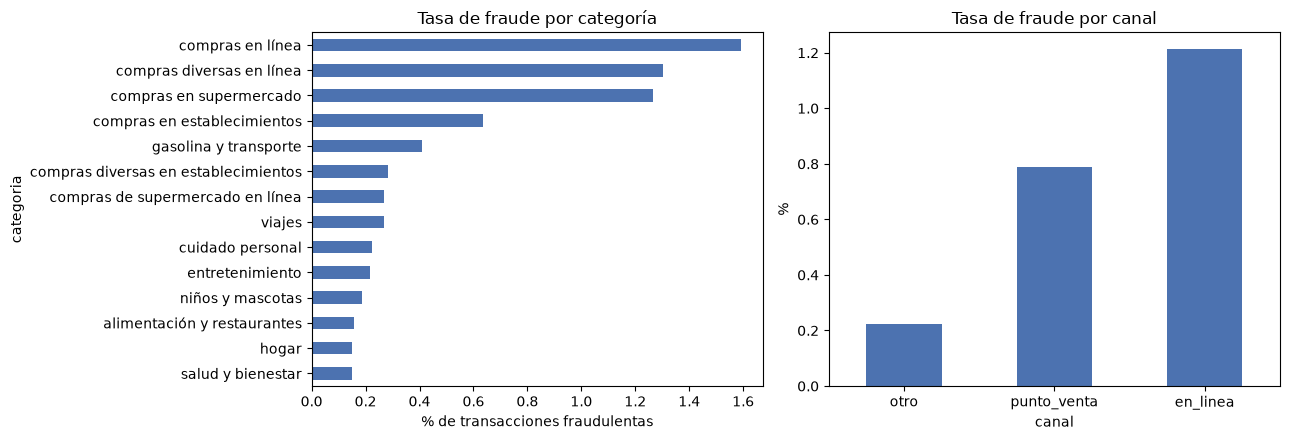

In [14]:
# Canal (en línea / punto de venta / otro) a partir de la categoría en español
df["canal"] = V.canal_desde_categoria(df["categoria"]).values
df["hora"] = df["fecha_hora"].dt.hour

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
(df.groupby("categoria")["es_fraude"].mean().sort_values() * 100).plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_title("Tasa de fraude por categoría"); ax[0].set_xlabel("% de transacciones fraudulentas")
(df.groupby("canal")["es_fraude"].mean().sort_values() * 100).plot.bar(ax=ax[1], color="#4C72B0")
ax[1].set_title("Tasa de fraude por canal"); ax[1].set_ylabel("%"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

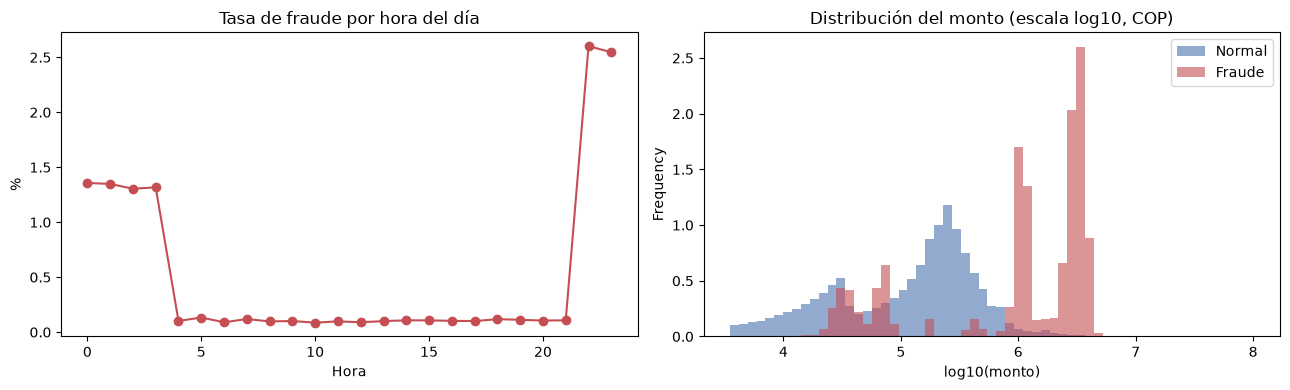

               count       mean        std     min       25%        50%  \
es_fraude                                                                 
0          1842743.0   236779.0   537418.0  3500.0   33635.0   165340.0   
1             9651.0  1857315.0  1368601.0  3710.0  840262.0  1365000.0   

                 75%          max  
es_fraude                          
0           288960.0  101321150.0  
1          3158278.0    4816140.0  


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(df.groupby("hora")["es_fraude"].mean() * 100).plot(ax=ax[0], marker="o", color="#C44E52")
ax[0].set_title("Tasa de fraude por hora del día"); ax[0].set_xlabel("Hora"); ax[0].set_ylabel("%")

bins = np.linspace(np.log10(df["monto"].min()), np.log10(df["monto"].max()), 60)
for etiqueta, color in [(0, "#4C72B0"), (1, "#C44E52")]:
    np.log10(df.loc[df["es_fraude"] == etiqueta, "monto"]).plot.hist(
        bins=bins, ax=ax[1], alpha=0.6, density=True, color=color, label="Fraude" if etiqueta else "Normal")
ax[1].set_title("Distribución del monto (escala log10, COP)"); ax[1].set_xlabel("log10(monto)"); ax[1].legend()
plt.tight_layout(); plt.show()

print(df.groupby("es_fraude")["monto"].describe().round(0))

In [16]:
# Género y edad: solo descriptivo (no entran al modelo principal)
df["edad"] = ((df["fecha_hora"] - df["fecha_nacimiento"]).dt.days / 365.25).astype(int)
df["grupo_edad"] = pd.cut(df["edad"], bins=[0, 30, 45, 60, 120], labels=["<30", "30-44", "45-59", "60+"])
print(df.groupby("genero")["es_fraude"].agg(["count", "mean"]))
print(df.groupby("grupo_edad", observed=True)["es_fraude"].agg(["count", "mean"]))

tx_por_cliente = df.groupby("cliente_id").size()
print("\nTransacciones por cliente:\n", tx_por_cliente.describe().round(1))

          count      mean
genero                   
F       1014749  0.004828
M        837645  0.005673
             count      mean
grupo_edad                  
<30         377444  0.005071
30-44       628231  0.004040
45-59       476380  0.005840
60+         370339  0.006526

Transacciones por cliente:
 count     999.0
mean     1854.2
std      1175.6
min         6.0
25%       740.0
50%      1471.0
75%      2917.0
max      4392.0
dtype: float64


**Hallazgos del EDA**
- **Desbalance:** solo 9.651 de 1.852.394 transacciones son fraude (0,52 %): 0,58 % en `fraudTrain` y 0,39 % en `fraudTest`. Un modelo que dijera "nada es fraude" acertaría el 99,5 %, por eso no se usa la exactitud sino PR-AUC y precision@K, y el modelo se entrena con `class_weight="balanced"`.
- **Categorías y canal:** las de más fraude son compras en línea (≈1,6 %), compras diversas en línea (≈1,3 %) y compras en supermercado (≈1,25 %); las de menos, salud y bienestar, hogar y alimentación (≈0,15 %). Por canal: en línea ≈1,2 %, punto de venta ≈0,8 %, otro ≈0,2 %.
- **Horas:** entre las 22:00 y las 23:59 la tasa sube a ≈2,5 % y entre las 0:00 y las 3:59 a ≈1,3 %, frente a ≈0,1 % el resto del día. Justifica la variable `hora` y la regla RD-03 (22:00 a 4:00).
- **Montos:** la mediana de un fraude (≈$1.365.000) es unas 8 veces la de una transacción normal (≈$165.000). La mayoría de fraudes está entre $1 y $4 millones, con un grupo pequeño de montos bajos que pueden ser compras de prueba. El fraude no son los montos más extremos: lo que delata es un monto alto *para ese cliente*.
- **Género y edad:** diferencias pequeñas (hombres 0,57 % y mujeres 0,48 %; 60+ años 0,65 % y 30–44 años 0,40 %). No entran al modelo principal para evitar sesgo; se evalúan en el experimento del notebook 02.

Estos hallazgos justifican las variables de historial y las reglas RD-01 a RD-04 del documento de modelado.

## 7. Tablas de ejemplo para el backend (opcionales)
Se exportan clientes, comercios y transacciones limpias, en COP y con categorías en español. El backend **no está obligado a usar estos datos**: puede crear sus propios clientes y comercios, siempre que respete esta estructura, use las 14 categorías en español y que cada cliente tenga transacciones anteriores (historial).

Si se usan, el **desplazamiento de fechas** (para que la transacción más reciente quede en el día de la carga) lo hace el backend al cargarlas, sumando a todas el mismo número de días.

In [17]:
clientes = (
    df.sort_values("fecha_hora")
      .drop_duplicates("cliente_id", keep="last")
      [["cliente_id", "nombre", "apellido", "genero", "ocupacion", "fecha_nacimiento",
        "ciudad", "estado", "tarjeta_ultimos4"]]
      .rename(columns={"cliente_id": "id"})
      .sort_values("id")
)
comercios = (
    df.drop_duplicates("comercio_id")[["comercio_id", "comercio"]]
      .assign(categoria=lambda x: x["comercio_id"].map(categoria_comercio))
      .assign(canal=lambda x: V.canal_desde_categoria(x["categoria"]).values)
      .rename(columns={"comercio_id": "id", "comercio": "nombre"})
      .sort_values("id")
)
transacciones = (
    df.sort_values("fecha_hora")
      .assign(id=lambda x: [f"TX-{i+1:07d}" for i in range(len(x))], origen="csv", estado_analisis="pendiente")
      [["id", "cliente_id", "comercio_id", "monto", "fecha_hora", "categoria", "canal",
        "origen", "estado_analisis", "es_fraude", "id_origen"]]
      .rename(columns={"es_fraude": "etiqueta_dataset"})
)
clientes.to_csv(RUTA_PROCESADOS / "clientes.csv", index=False)
comercios.to_csv(RUTA_PROCESADOS / "comercios.csv", index=False)
transacciones.to_csv(RUTA_PROCESADOS / "transacciones.csv", index=False)
print(clientes.shape, comercios.shape, transacciones.shape)
comercios.head()

(999, 9) (693, 4) (1852394, 11)


,id,nombre,categoria,canal
1251,M-0001,Abbott-Rogahn,entretenimiento,otro
1062,M-0002,Abbott-Steuber,cuidado personal,otro
2053,M-0003,Abernathy and Sons,alimentación y restaurantes,otro
195,M-0004,Abshire PLC,entretenimiento,otro
114,M-0005,"Adams, Kovacek and Kuhlman",compras de supermercado en línea,en_linea


## 8. Variables de historial y variables del modelo
Se calculan con `variables.calcular_historial`, que usa **solo transacciones anteriores** del mismo cliente (ventanas con `closed="left"` y `shift()`). Por eso calcular sobre todo el dataset junto no genera fuga: la fila de una fecha nunca ve filas posteriores.

Estas son exactamente las 4 variables que calcula el backend (RN-16). Las demás (canal, hora, día, proporciones del monto) las calcula el pipeline del modelo con `variables.construir_variables`.

> **Distancia eliminada:** en una primera versión se calculaba la distancia cliente–comercio, pero su mediana era prácticamente igual en fraude y en normales (≈78 km), es decir, no aporta información. Se quitó del modelo y por eso el backend ya no envía coordenadas.

In [18]:
%%time
df = V.calcular_historial(df)
df[["cliente_id", "fecha_hora", "categoria", "monto", "monto_promedio_30d",
    "monto_promedio_categoria", "primera_vez_categoria", "segundos_desde_ultima"]].head(8)

CPU times: total: 53 s
Wall time: 55 s


,cliente_id,fecha_hora,categoria,monto,monto_promedio_30d,monto_promedio_categoria,primera_vez_categoria,segundos_desde_ultima
1017,C-0001,2019-01-01 12:47:15,compras diversas en línea,25445.0,25445.000000,25445.0,1,2592000.0
2724,C-0001,2019-01-02 08:44:57,gasolina y transporte,185290.0,25445.000000,185290.0,1,71862.0
2726,C-0001,2019-01-02 08:47:36,gasolina y transporte,287280.0,105367.500000,185290.0,0,159.0
2882,C-0001,2019-01-02 12:38:14,niños y mascotas,121765.0,166005.000000,121765.0,1,13838.0
2907,C-0001,2019-01-02 13:10:46,hogar,95130.0,154945.000000,95130.0,1,1952.0
4135,C-0001,2019-01-03 13:56:35,compras en línea,24045.0,142982.000000,24045.0,1,89149.0
4337,C-0001,2019-01-03 17:05:10,alimentación y restaurantes,29505.0,123159.166667,29505.0,1,11315.0
5467,C-0001,2019-01-04 13:59:55,hogar,409885.0,109780.000000,95130.0,0,75285.0


In [19]:
# Comparación de las variables del modelo entre clases.
vars_modelo = V.construir_variables(df[V.COLUMNAS_API])
vars_modelo["es_fraude"] = df["es_fraude"].values

# Variables continuas: se compara la mediana
continuas = [v for v in V.VARIABLES_NUMERICAS if v != "primera_vez_categoria"]
display(vars_modelo.groupby("es_fraude")[continuas].median().T.round(2))

# primera_vez_categoria es 0/1: su mediana siempre sale 0, así que se compara la PROPORCIÓN de unos
print("Proporción de transacciones que son la primera del cliente en esa categoría:")
print(vars_modelo.groupby("es_fraude")["primera_vez_categoria"].mean().map("{:.2%}".format))

es_fraude,0,1
log_monto,12.02,14.13
hora,14.00,22.00
dia_semana,3.00,3.00
ratio_monto_30d,0.67,4.30
ratio_monto_categoria,0.82,3.52
log_segundos_desde_ultima,9.67,8.53


Proporción de transacciones que son la primera del cliente en esa categoría:
es_fraude
0    0.69%
1    5.67%
Name: primera_vez_categoria, dtype: str


### ¿Qué pasa con clientes de poco historial o que compran en una categoría nueva?
En la demo un cliente puede tener pocas compras (por ejemplo 8 en una categoría y luego una en otra). Aquí se revisa cuántas transacciones del dataset están en esa situación y cómo se comporta el fraude en ellas, para saber si el modelo tiene ejemplos de esos casos.

In [20]:
# Número de transacciones anteriores de cada cliente al momento de cada transacción
df["tx_previas_cliente"] = df.groupby("cliente_id").cumcount()

print("Transacciones que son la primera del cliente en esa categoría:",
      f"{df['primera_vez_categoria'].sum():,} ({df['primera_vez_categoria'].mean():.2%})")
print("\nTasa de fraude según si es la primera vez en la categoría:")
print(df.groupby("primera_vez_categoria")["es_fraude"].agg(transacciones="size", tasa_fraude="mean"))

tramos = pd.cut(df["tx_previas_cliente"], bins=[-1, 0, 10, 50, 200, 10**6],
                labels=["0 (primera)", "1-10", "11-50", "51-200", "más de 200"])
print("\nTasa de fraude según cuántas transacciones previas tenía el cliente:")
print(df.groupby(tramos, observed=True)["es_fraude"].agg(transacciones="size", tasa_fraude="mean"))

Transacciones que son la primera del cliente en esa categoría: 13,171 (0.71%)

Tasa de fraude según si es la primera vez en la categoría:
                       transacciones  tasa_fraude
primera_vez_categoria                            
0                            1839223     0.004950
1                              13171     0.041531

Tasa de fraude según cuántas transacciones previas tenía el cliente:
                    transacciones  tasa_fraude
tx_previas_cliente                            
0 (primera)                   999     0.091091
1-10                         9855     0.083815
11-50                       36358     0.011579
51-200                     136200     0.008319
más de 200                1668982     0.004302


## 9. Particiones train / valid / test sin fuga
- **Test:** `fraudTest.csv` completo (transacciones posteriores a todo lo demás). No se toca hasta la evaluación final.
- **Valid:** el último 20 % por fecha de `fraudTrain.csv`. Se usa para comparar modelos y elegir el umbral.
- **Train:** el resto de `fraudTrain.csv`.

La partición es **por tiempo** y no aleatoria: así el modelo se evalúa con transacciones del futuro, como pasará en la aplicación.

In [24]:
es_test = df["archivo_origen"] == "fraudTest"
fechas_train = df.loc[~es_test, "fecha_hora"]
fecha_corte = fechas_train.quantile(1 - PROPORCION_VALID)

df["particion"] = np.where(es_test, "test", np.where(df["fecha_hora"] < fecha_corte, "train", "valid"))

resumen = df.groupby("particion").agg(
    filas=("es_fraude", "size"), fraudes=("es_fraude", "sum"), tasa_fraude=("es_fraude", "mean"),
    desde=("fecha_hora", "min"), hasta=("fecha_hora", "max"),
).loc[["train", "valid", "test"]]
resumen

,filas,fraudes,tasa_fraude,desde,hasta
particion,,,,,
train,1037340,5968,0.005753,2019-01-01 00:00:18,2020-03-06 07:15:17
valid,259335,1538,0.005931,2020-03-06 07:16:43,2020-06-21 12:13:37
test,555719,2145,0.003860,2020-06-21 12:14:25,2020-12-31 23:59:34


In [22]:
# Verificaciones contra fuga
assert df.loc[df.particion == "train", "fecha_hora"].max() <= df.loc[df.particion == "valid", "fecha_hora"].min()
assert df.loc[df.particion == "valid", "fecha_hora"].max() <= df.loc[df.particion == "test", "fecha_hora"].min()
assert df["id_origen"].is_unique, "Hay transacciones repetidas entre particiones"
print("OK: las particiones no se solapan en el tiempo y no hay transacciones repetidas")

OK: las particiones no se solapan en el tiempo y no hay transacciones repetidas


## 10. Guardar datos procesados y evidencia de procedencia

In [23]:
COLUMNAS_GUARDAR = (["id_origen", "cliente_id", "comercio_id"] + V.COLUMNAS_API +
                   ["genero", "edad", "ocupacion", "es_fraude", "particion"])
for p in ["train", "valid", "test"]:
    df.loc[df.particion == p, COLUMNAS_GUARDAR].to_parquet(RUTA_PROCESADOS / f"{p}.parquet", index=False)

diccionario = pd.DataFrame([
    ("id_origen", "trans_num", "ID único de la transacción en el dataset"),
    ("cliente_id", "cc_num", "ID del cliente (C-0001…); reemplaza el número de tarjeta"),
    ("comercio_id", "merchant", "ID del comercio (M-0001…)"),
    ("monto", "amt", "Monto en COP (amt × 3.500)"),
    ("fecha_hora", "trans_date_trans_time", "Fecha y hora de la transacción"),
    ("categoria", "category", "Categoría del comercio en español (14 valores, ver V.TRADUCCION_CATEGORIAS)"),
    ("monto_promedio_30d", "calculada", "Promedio del cliente en los 30 días previos; sin historial = monto"),
    ("monto_promedio_categoria", "calculada", "Promedio anterior del cliente en esa categoría; sin historial = monto"),
    ("primera_vez_categoria", "calculada", "1 si el cliente nunca había comprado en esa categoría"),
    ("segundos_desde_ultima", "calculada", "Segundos desde la transacción anterior; sin historial = 2.592.000"),
    ("genero / edad / ocupacion", "gender / dob / job", "Solo para el experimento de sesgo"),
    ("es_fraude", "is_fraud", "Etiqueta (0/1)"),
    ("particion", "calculada", "train / valid / test por fecha"),
], columns=["columna", "origen_dataset", "descripcion"])
diccionario.to_csv(RUTA_PROCESADOS / "diccionario_datos.csv", index=False)

metadata = {
    "dataset": "Credit Card Transactions Fraud Detection Dataset (Sparkov)",
    "url": "https://www.kaggle.com/datasets/kartik2112/fraud-detection",
    "fecha_descarga": "2026-11-21",
    "fecha_procesamiento": datetime.now().isoformat(timespec="seconds"),
    "tasa_cop_por_usd": TASA_COP_POR_USD,
    "categorias": V.CATEGORIAS,
    "semilla": SEMILLA,
    "fecha_corte_valid": str(fecha_corte),
    "particiones": {p: {"filas": int(r.filas), "fraudes": int(r.fraudes), "tasa_fraude": round(float(r.tasa_fraude), 6)}
                    for p, r in resumen.iterrows()},
    "clientes": int(clientes.shape[0]),
    "comercios": int(comercios.shape[0]),
}
(RUTA_PROCESADOS / "metadata_datos.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(metadata, indent=2, ensure_ascii=False))

{
  "dataset": "Credit Card Transactions Fraud Detection Dataset (Sparkov)",
  "url": "https://www.kaggle.com/datasets/kartik2112/fraud-detection",
  "fecha_descarga": "2026-11-21",
  "fecha_procesamiento": "2026-11-21T16:05:00",
  "tasa_cop_por_usd": 3500,
  "categorias": [
    "alimentación y restaurantes",
    "compras de supermercado en línea",
    "compras diversas en establecimientos",
    "compras diversas en línea",
    "compras en establecimientos",
    "compras en línea",
    "compras en supermercado",
    "cuidado personal",
    "entretenimiento",
    "gasolina y transporte",
    "hogar",
    "niños y mascotas",
    "salud y bienestar",
    "viajes"
  ],
  "semilla": 42,
  "fecha_corte_valid": "2020-03-06 07:15:34.200000",
  "particiones": {
    "train": {
      "filas": 1037340,
      "fraudes": 5968,
      "tasa_fraude": 0.005753
    },
    "valid": {
      "filas": 259335,
      "fraudes": 1538,
      "tasa_fraude": 0.005931
    },
    "test": {
      "filas": 555719,
   

## 11. Resumen
- Datos con procedencia documentada (sección 1 y `metadata_datos.json`).
- Columnas y categorías en español, montos en COP (tasa 3.500), datos personales que no se usan eliminados.
- EDA con hallazgos sobre desbalance, categorías, canal, horas, montos y grupos.
- Variables de historial calculadas solo con el pasado (sin fuga); la distancia se descartó por no aportar.
- Particiones temporales train / valid / test verificadas.

Siguiente: `02_modelo.ipynb` (baseline y modelo final).